# Example of the `aitlas` toolbox in the context of multi class image classification

This notebook shows a sample implementation of a multi class image classification using the `aitlas` toolbox and the SAT 4 dataset.

In [ ]:
from aitlas.datasets import SAT4Dataset
from aitlas.models import ResNet50
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor
from aitlas.utils import image_loader
import scipy.io
import csv

## Load the dataset

In [11]:
dataset_config = {
    "mat_file": "/home/dragik/data/FAIR_EO/SAT-4/sat-4-full.mat",
    "csv_file": "/home/dragik/data/FAIR_EO/SAT-4/X_train_sat4.csv",
    "mode": "train"
}
dataset = SAT4Dataset(dataset_config)
print(f"Total number of patches: {len(dataset)}")

Total number of patches: 400000


## Show images from the dataset

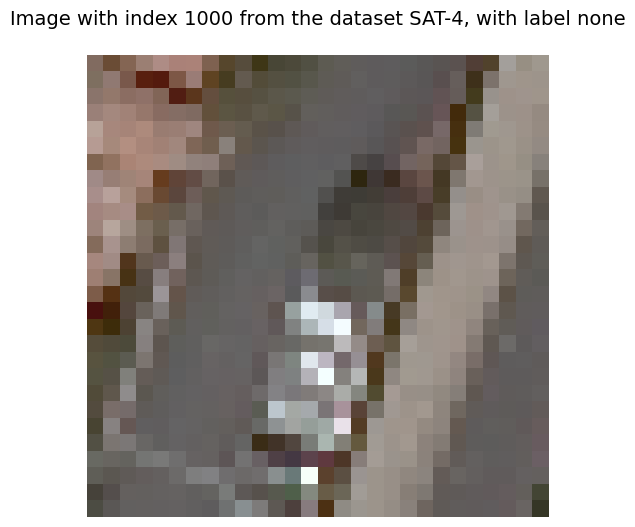

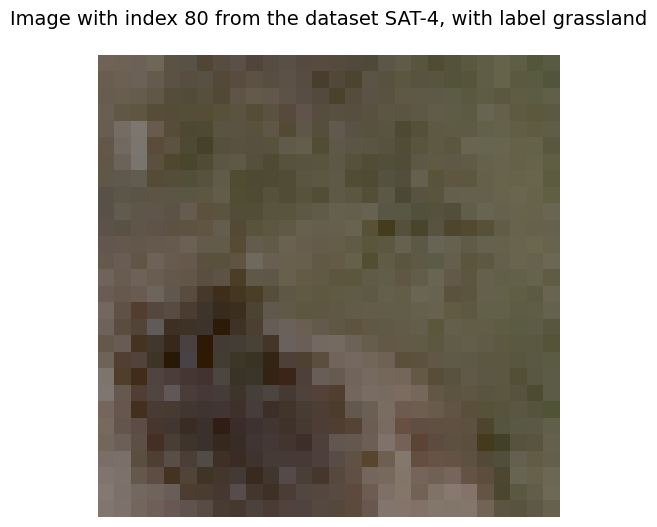

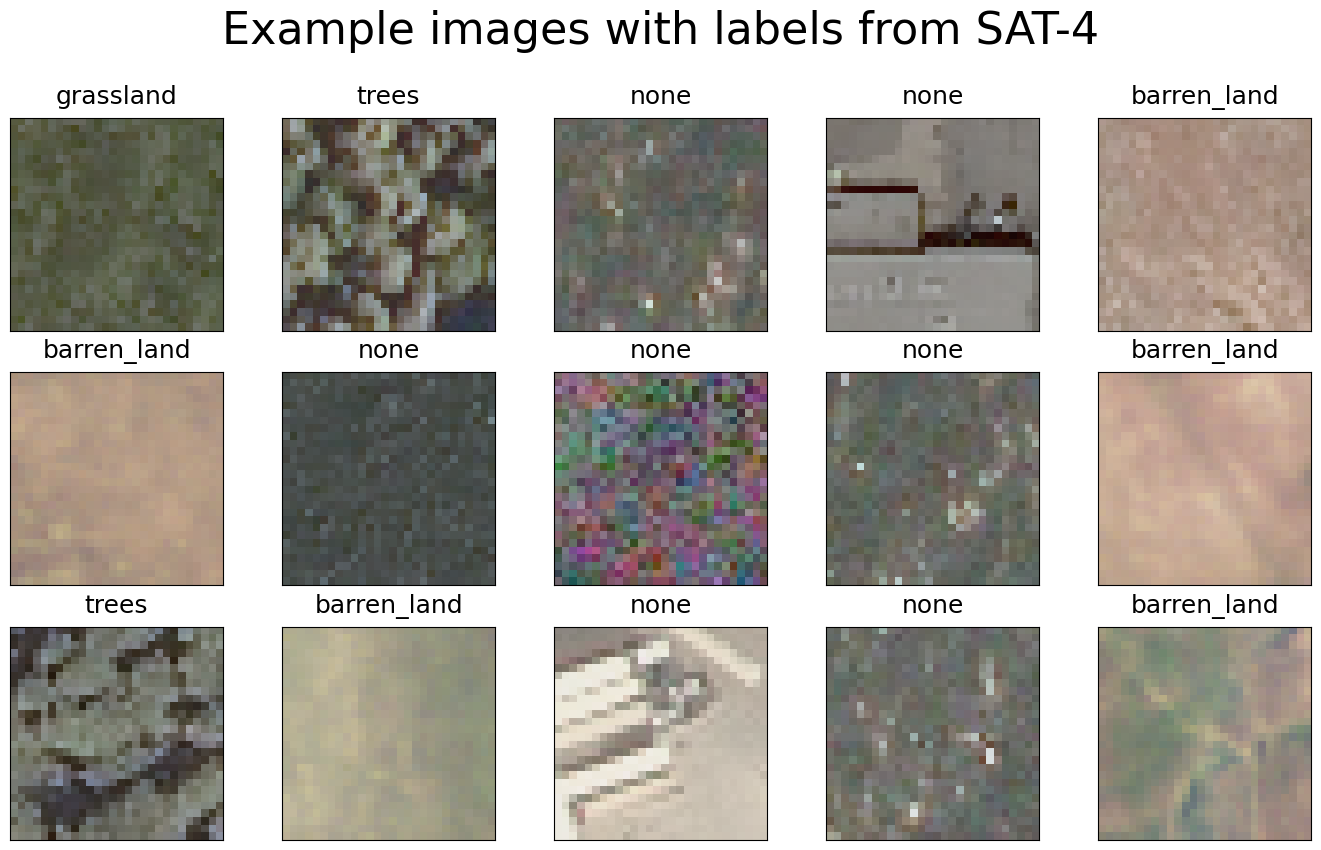

In [12]:
fig1 = dataset.show_image(1000)
fig2 = dataset.show_image(80)
fig3 = dataset.show_batch(15)

## Inspect the data

In [9]:
dataset.show_samples()

,Image ID,Label
0,0,trees
1,1,trees
2,2,trees
3,3,trees
4,4,trees
5,5,trees
6,6,barren_land
7,7,barren_land
8,8,grassland
9,9,barren_land


In [13]:
dataset.data_distribution_table()

,Label,Count
0,barren_land,102774
1,grassland,61068
2,none,175198
3,trees,60960


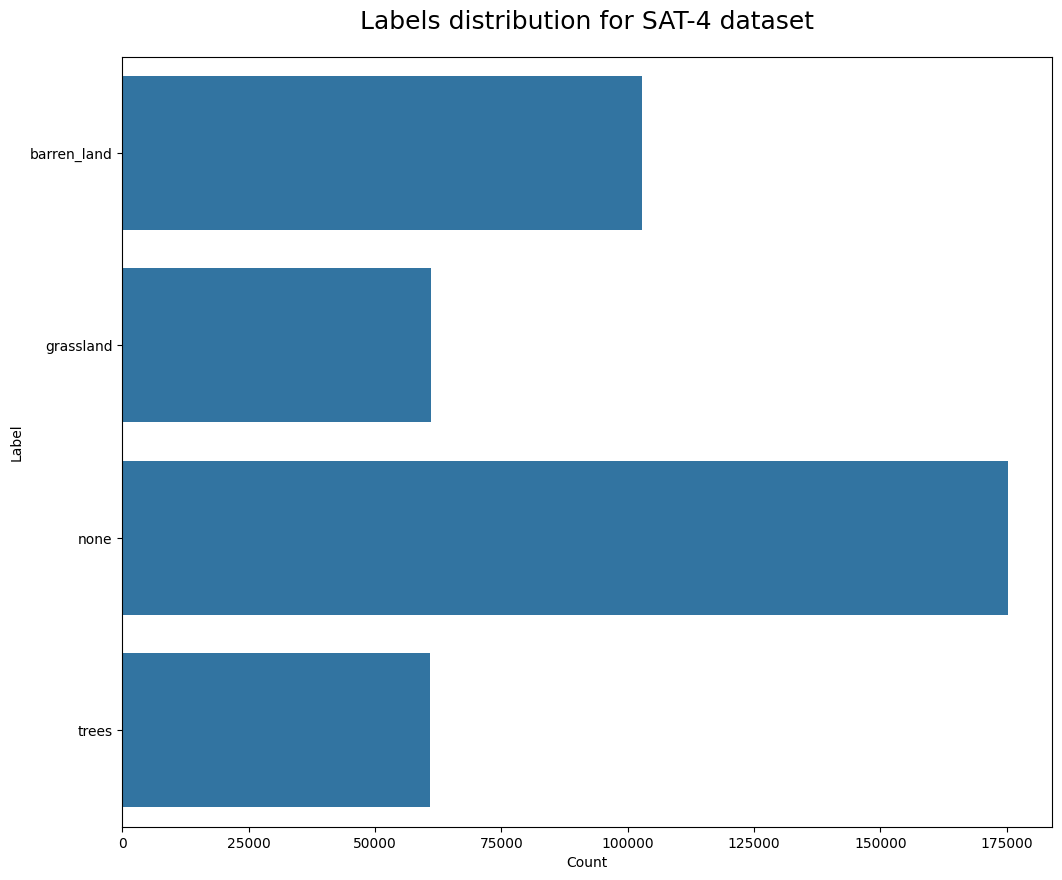

In [11]:
fig = dataset.data_distribution_barchart()

## Load train and test splits

In [9]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "mat_file": "/home/dragik/data/FAIR_EO/SAT-4/sat-4-full.mat",
    "csv_file": "/home/dragik/data/FAIR_EO/SAT-4/X_train_sat4.csv",
    "mode": "train"
}

train_dataset = SAT4Dataset(train_dataset_config)
train_dataset.transform = ResizeCenterCropFlipHVToTensor() 

test_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "mat_file": "/home/dragik/data/FAIR_EO/SAT-4/sat-4-full.mat",
    "csv_file": "/home/dragik/data/FAIR_EO/SAT-4/X_test_sat4.csv",
    "mode": "test",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

test_dataset = SAT4Dataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(400000, 100000)

## Setup and create the model for training

In [10]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/experiments/sat4"
model_config = {
    "num_classes": 4, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = ResNet50(model_config)
model.prepare()

## Training and evaluation

In [11]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=test_dataset,
    run_id='1',
)

2025-07-16 11:26:26,634 INFO Starting training.
training: 100%|██████████| 12500/12500 [15:31<00:00, 13.41it/s]
2025-07-16 11:41:58,592 INFO epoch: 1, time: 932, loss:  0.01066
testing on train set: 100%|██████████| 12500/12500 [05:02<00:00, 41.29it/s]
2025-07-16 11:47:02,003 INFO Accuracy:0.9999975, Precision Micro:0.9999975, Precision Macro:0.9999959062699569, Precision Weighted:0.9999975000409373, Precision per Class:[1.         1.         0.99998363 1.        ], Recall Micro:0.9999975, Recall Macro:0.9999975674781559, Recall Weighted:0.9999975, Recall per Class:[0.99999027 1.         1.         1.        ], F1_score Micro:0.9999974999999994, F1_score Macro:0.99999673685138, F1_score Weighted:0.9999975000041527, F1_score per Class:[0.99999513 1.         0.99999181 1.        ]
testing on validation set: 100%|██████████| 3125/3125 [01:10<00:00, 44.32it/s]
2025-07-16 11:48:12,523 INFO Accuracy:0.9611, Precision Micro:0.9611, Precision Macro:0.9402894151856682, Precision Weighted:0.9654

6.074982419572766e-05

## Predictions

2025-07-17 06:33:54,273 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/sat4/checkpoint.pth.tar
2025-07-17 06:33:54,447 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/sat4/checkpoint.pth.tar at epoch 11


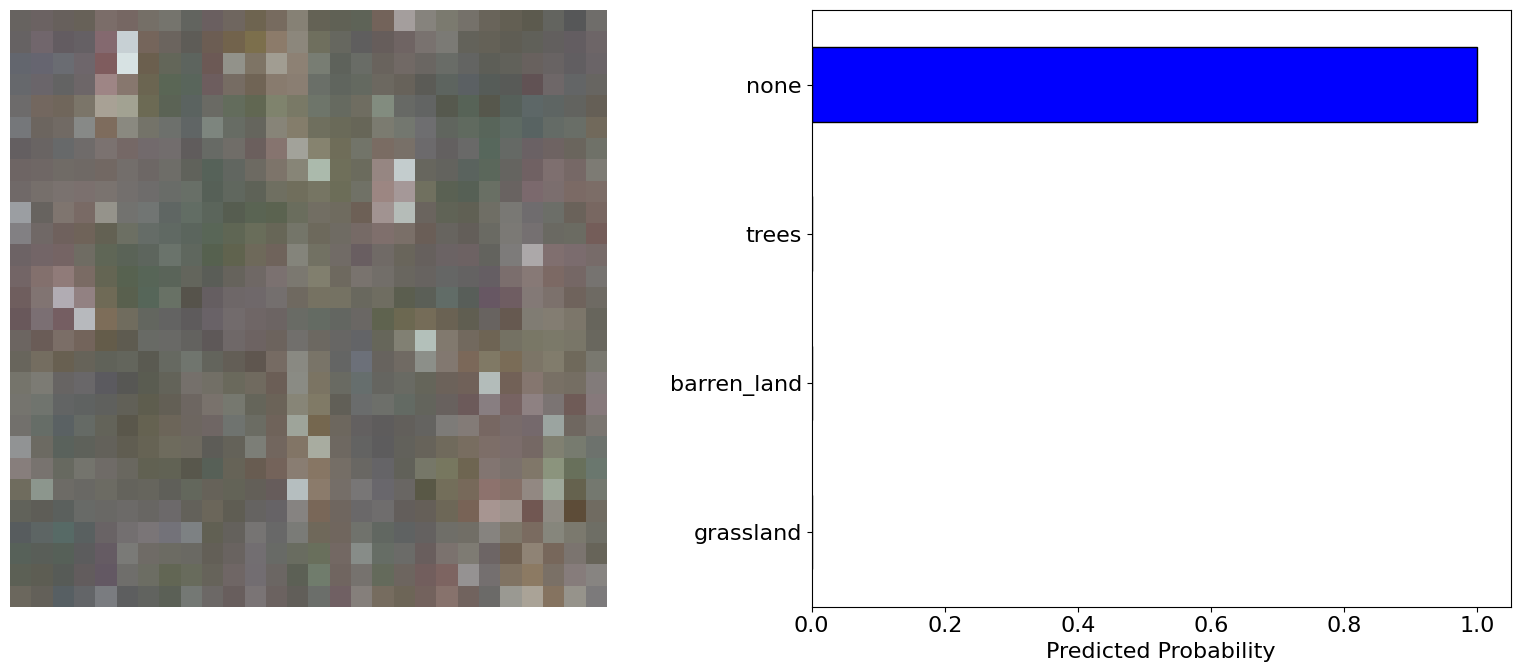

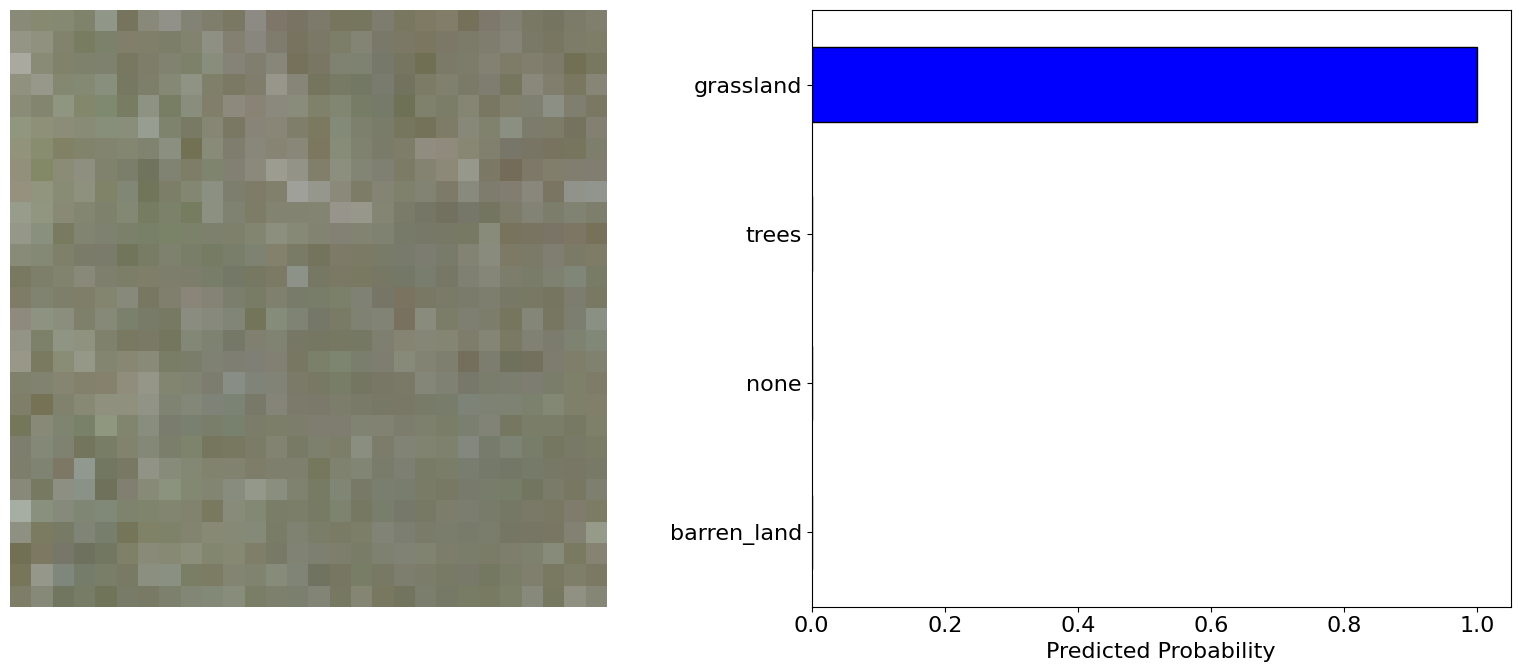

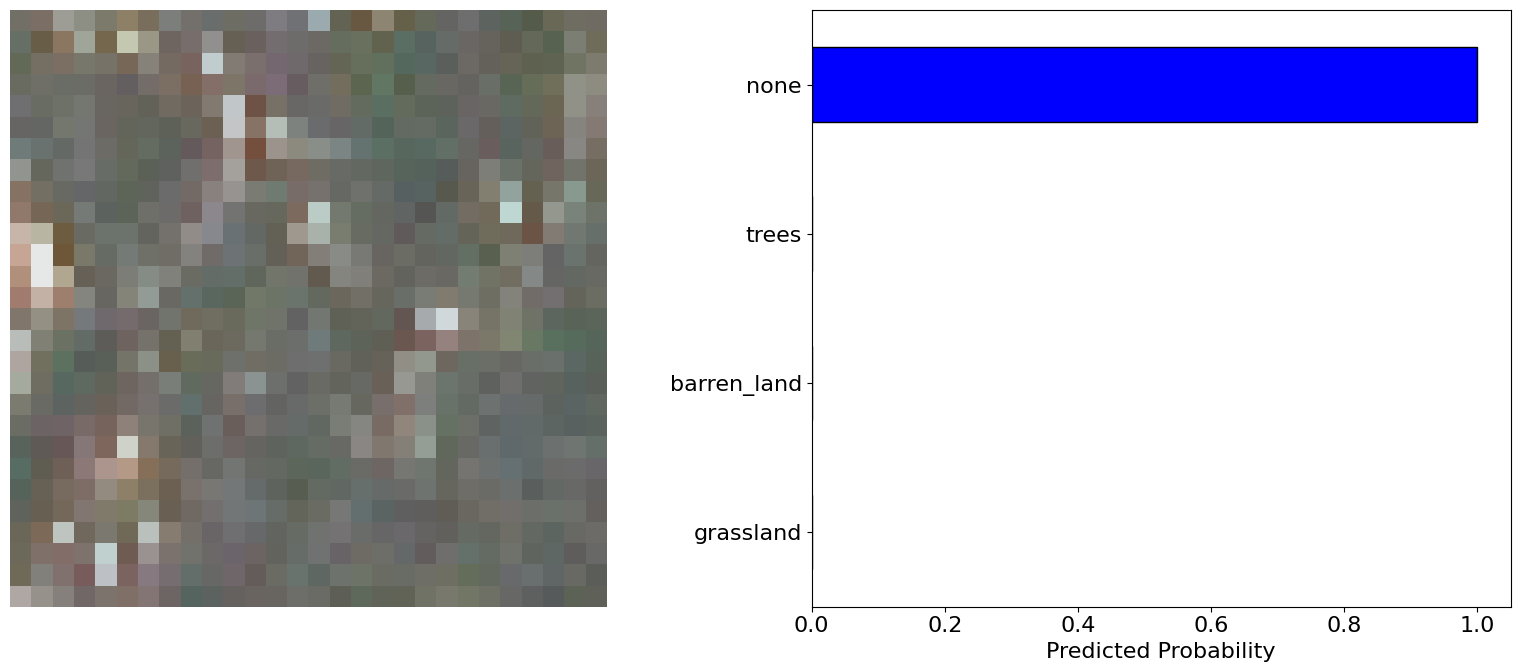

In [ ]:
labels = ["barren_land", "trees", "grassland", "none"]
transform = ResizeCenterCropToTensor()

model_path = "/home/dragik/data/FAIR_EO/experiments/sat4/checkpoint.pth.tar"
model.load_model(model_path)

mat_file = "/home/dragik/data/FAIR_EO/SAT-4/sat-4-full.mat"
csv_file = "/home/dragik/data/FAIR_EO/SAT-4/X_test_sat4.csv"
mode = 'test'
indices = None

with open(csv_file) as infile:
    data = csv.reader(infile)
    indices = [int(row[0]) for row in data]
    indices = sorted(indices, reverse=True)

mat_data = scipy.io.loadmat(mat_file)
images = mat_data[f"{mode}_x"].transpose(3, 0, 1, 2)

valid_indices = [idx for idx in indices if idx < len(images)]
images = images[valid_indices]
images = images[:, :, :, 0:3]

image = images[0]
fig = model.predict_image(image, labels, transform)

image = images[10]
fig = model.predict_image(image, labels, transform)

image = images[20]
fig = model.predict_image(image, labels, transform)